# Jude 2026 intended speech (neural to phonemes, CTC)

Decodes the neural features of the **125,000-word sentence task** into the **ARPAbet phoneme sequence** of the cued sentence, the dataset's brain-to-text task. T17 is anarthric, so attempted speech leaves no acoustic trace and the only label is the prompt. The target is therefore the prompt's **dictionary pronunciation** (`utils.CUE_PHONEMES`, built once with the authors' `g2p_en` recipe), not a measurement of what T17 produced, and it carries no per-phoneme timing. That makes it an unaligned sequence per trial, so the model trains with **CTC** and reports **phoneme error rate (PER)** before any language model.

Each trial is one variable-length segment from the go cue to the end of the sentence: a `RaggedSegmenter` triggered on the `Sentence` event reads the two neural streams through `NeuralFeatureExtractor` and the target through `PhonemeEncoder`. The input keeps the 6v and 55b arrays that fed the online decoder (256 electrodes, two features each). One whole session is held out, so the score is a cross-day number from a small model, far below the paper's RNN with a language model.

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

from neuralshed.text import PhonemeVocab, ctc_min_input_length
from neuralshed.extractors import NeuralFeatureExtractor, PhonemeEncoder
from neuralshed.dataloader import RaggedSegmenter, RaggedCollator, PadSpec
from neuralshed.datasets.jude_2026_speech import study, utils
from neuralshed.datasets.utils import dataset_dir

pd.set_option("display.max_columns", None)
torch.manual_seed(0)

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("jude_2026_speech") / "data"
s = study.Jude2026IntendedSpeech(path=root)
s.download()

FS = 50.0                                  # the authors' decoder rate, 10 ms bins compressed to 20 ms
VAL_SESSION = "t17.2024.05.07"             # held out whole, one of the sessions the authors' code holds out
N_DECODER = utils.N_ELECTRODES_DECODER     # 256: the 6v and 55b columns, first in Study order
N_INPUT = 2 * N_DECODER                    # threshold crossings and spike-band power of those columns
VOCAB = PhonemeVocab.canonical()           # 41 classes: blank + 39 phonemes + word boundary
print(VOCAB)

2026-10-15 12:10:56 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/jude_2026_speech/data/Jude2026IntendedSpeech.


2026-10-15 12:10:56 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/jude_2026_speech/data/Jude2026IntendedSpeech (skipped 0 non-owned items).


PhonemeVocab(version='v1', n_classes=41)


## 1. The 125k sentence trials, one session held out

The task ran on eight sessions. The three April sessions recorded only the four decoder arrays (256 channels) and the other five recorded all six (384). This example keeps the five 384-channel sessions so every block shares one layout. Session 2024.05.07 is the validation set, with open- and closed-loop blocks. Training and validation never share a block or a day.

The 125k prompts come from a large corpus, so few repeat across days. The number of validation prompts that also occur in a training session is printed here, and section 6 reports PER with and without them.

In [2]:
timelines = pd.DataFrame(s.iter_timelines())
is_task = timelines.task_family.str.startswith("sentence_125k")
is_full = ~timelines.session.isin(utils.SESSIONS_256)
chosen = timelines.index[is_task & is_full].tolist()

events = study.Jude2026IntendedSpeech(path=root, query=f"timeline_index in {chosen}").run()
events["split"] = np.where(events.session == VAL_SESSION, "val", "train")

sentences = events[events.type == "Sentence"]
print("blocks:", events.timeline.nunique(), "| sentence trials:", len(sentences))
display(pd.crosstab([sentences.split, sentences.session], sentences.loop_type, margins=True))

train_prompts = set(sentences[sentences.split == "train"].text)
val_sentences = sentences[sentences.split == "val"]
n_seen = int(val_sentences.text.isin(train_prompts).sum())
print(f"validation prompts also cued on a training day: {n_seen} of {len(val_sentences)}")

blocks: 44 | sentence trials: 1651


loop_type             closed  open   All
split session                           
train t17.2024.04.02      11   252   263
      t17.2024.05.06       0   330   330
      t17.2024.05.13       0    80    80
      t17.2024.05.14     178    80   258
      t17.2024.05.28      80   240   320
val   t17.2024.05.07     200   200   400
All                      469  1182  1651

validation prompts also cued on a training day: 35 of 400


## 2. One segment per trial

- `tx` and `sbp`: the two streams read separately at 50 Hz, `SpikeCounts` as a rate in Hz and `BandPower` in its native unit, each `(384, T)` in Study order (6v, 55b, 6d).
- `target`: the ARPAbet ids of the `Sentence`'s `phonemes` column through the frozen 41-class vocabulary, the layout `card_2024` uses too.

A CTC target needs at least `len(ids) + adjacent repeats` emission frames. Trials shorter than that after the two stride-2 convolutions are dropped and reported.

In [3]:
CACHE = dict(folder=dataset_dir("jude_2026_speech") / "cache", keep_in_ram=False)   # extractor disk cache

segmenter = RaggedSegmenter(
    extractors={
        "tx": NeuralFeatureExtractor(target_unit="Hz", event_types=("SpikeCounts",), frequency=FS, infra=CACHE),
        "sbp": NeuralFeatureExtractor(target_unit="native", event_types=("BandPower",), frequency=FS, infra=CACHE),
        "target": PhonemeEncoder(aggregation="trigger"),
    },
    trigger_query="type == 'Sentence'",
    duration=None,                                   # each segment inherits its sentence duration
    metadata_columns=("split", "session", "timeline", "loop_type", "text"),
)
dataset = segmenter.apply(events)
dataset.prepare()


def conv_len(n):
    """Output length of one conv with kernel 5, stride 2, padding 2."""
    return (n + 2 * 2 - 5) // 2 + 1


def emit_len(n):
    return conv_len(conv_len(n))


keep = []
dropped = []
for i in range(len(dataset)):
    item = dataset[i]
    frames = emit_len(item.data["tx"].shape[-1])
    need = ctc_min_input_length(item.data["target"].tolist())
    keep.append(frames >= need)
    if frames < need:
        dropped.append((item.metadata["text"], frames, need))
dataset = dataset.select(np.array(keep))
print(dataset)
print(f"dropped {len(dropped)} trials whose emission frames cannot hold the target:")
for text, frames, need in dropped:
    print(f"  {frames} frames < {need} needed: {text!r}")

2026-10-15 12:10:57 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


2026-10-15 12:10:58 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


2026-10-15 12:10:58 - INFO - neuralset.dataloader:222 - Preparing extractor: PhonemeEncoder


RaggedSegmentDataset(1651 segments, extractors: tx, sbp, target, metadata: split, session, timeline, loop_type, text)
dropped 0 trials whose emission frames cannot hold the target:


## 3. Normalize: block means, then one scale from the training split

The authors' pipeline subtracts each block's own channel mean and divides by one global standard deviation. A block mean is a label-free statistic of that block's recording, so it is computed for every block, validation included, from the frames of its own trials. The standard deviation is fit on the training frames only. Both apply to the 512 decoder columns, the 6v and 55b arrays of each stream.

In [4]:
train_ds = dataset.select(dataset.metadata.split.eq("train").to_numpy())
val_ds = dataset.select(dataset.metadata.split.eq("val").to_numpy())
print(f"train trials: {len(train_ds)} | val trials: {len(val_ds)}")

collate = RaggedCollator(
    fields={
        "tx": PadSpec(axis=-1, pad_value=0),
        "sbp": PadSpec(axis=-1, pad_value=0),
        "target": PadSpec(axis=0, pad_value=0),
    }
)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, collate_fn=collate)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, collate_fn=collate)


def features(batch):
    """(B, 512, T) decoder columns of both streams and the (B, 1, T) valid-frame mask."""
    x = torch.cat([batch.data["tx"][:, :N_DECODER], batch.data["sbp"][:, :N_DECODER]], dim=1)
    mask = batch.valid_mask("tx").unsqueeze(1).to(x.dtype)
    return x * mask, mask


# per-block channel means over the frames of the block's trials
sums = {}
counts = {}
for b in DataLoader(dataset, batch_size=32, shuffle=False, collate_fn=collate):
    x, mask = features(b)
    for k, tl in enumerate(b.metadata["timeline"]):
        sums[tl] = sums.get(tl, 0.0) + x[k].sum(-1)
        counts[tl] = counts.get(tl, 0) + int(mask[k].sum())
block_mean = {tl: sums[tl] / counts[tl] for tl in sums}


def centered(batch):
    """Features with their own block mean removed, padded frames kept at zero."""
    x, mask = features(batch)
    mu = torch.stack([block_mean[tl] for tl in batch.metadata["timeline"]]).unsqueeze(-1)
    return (x - mu) * mask, mask


# one per-channel scale from the training frames
total_sq = torch.zeros(N_INPUT)
n_frames = 0
for b in train_loader:
    x, mask = centered(b)
    total_sq += (x ** 2).sum((0, 2))
    n_frames += int(mask.sum())
sd = (total_sq / n_frames).sqrt().view(1, N_INPUT, 1) + 1e-6


def normalized(batch):
    """(B, 512, T) input: block mean removed, training scale applied, padding at zero."""
    x, mask = centered(batch)
    return x / sd * mask

train trials: 1251 | val trials: 400


## 4. A compact CTC decoder

Two strided temporal convs (50 Hz to 12.5 Hz) + a 2-layer bidirectional GRU + a per-frame linear head over **41 classes** (blank + 40 phonemes), read as CTC emissions. The GRU runs on packed sequences, so a trial's emissions do not depend on how much padding its batch carries.

In [5]:
def frame_mask(lengths, n_frames):
    """(B, 1, n_frames) mask that is 1 on each trial's valid frames."""
    return (torch.arange(n_frames)[None, :] < lengths[:, None]).unsqueeze(1).to(torch.float32)


class CTCDecoder(nn.Module):
    def __init__(self, c_in=N_INPUT, n_classes=VOCAB.n_classes, hidden=128, p=0.2):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv1d(c_in, 256, 5, 2, 2), nn.ReLU(), nn.Dropout(p))
        self.conv2 = nn.Sequential(nn.Conv1d(256, 256, 5, 2, 2), nn.ReLU(), nn.Dropout(p))
        self.gru = nn.GRU(256, hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=p)
        self.head = nn.Linear(2 * hidden, n_classes)

    def forward(self, x, lengths):                   # x: (B, 512, T), lengths: (B,) valid bins
        # zero the frames past each trial's valid length, so the next layer sees only padding
        h = self.conv1(x)
        n1 = conv_len(lengths)
        h = h * frame_mask(n1, h.shape[-1])
        h = self.conv2(h)
        n2 = conv_len(n1)
        packed = pack_padded_sequence(h.transpose(1, 2), n2.cpu(), batch_first=True, enforce_sorted=False)
        packed, _ = self.gru(packed)
        h, _ = pad_packed_sequence(packed, batch_first=True, total_length=h.shape[-1])
        return self.head(h).log_softmax(-1), n2      # (B, T', 41), valid emission frames


model = CTCDecoder()
print(model)

CTCDecoder(
  (conv1): Sequential(
    (0): Conv1d(512, 256, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (conv2): Sequential(
    (0): Conv1d(256, 256, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (gru): GRU(256, 128, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (head): Linear(in_features=256, out_features=41, bias=True)
)


## 5. Train (CTC loss) and track phoneme error rate

In [6]:
def levenshtein(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[-1]


def greedy(logp, n):
    """(T', 41) log-probs over n valid frames -> collapsed phoneme ids."""
    out = []
    prev = -1
    for v in logp[:n].argmax(-1).tolist():
        if v != prev and v != VOCAB.BLANK:
            out.append(v)
        prev = v
    return out


def per(loader):
    """Phoneme error rate: Levenshtein edits over reference phonemes, summed over trials."""
    model.eval()
    err = 0
    tot = 0
    with torch.no_grad():
        for b in loader:
            logp, n_valid = model(normalized(b), b.lengths["tx"])
            for k in range(len(n_valid)):
                ref = b.data["target"][k, : b.lengths["target"][k]].tolist()
                err += levenshtein(greedy(logp[k], int(n_valid[k])), ref)
                tot += len(ref)
    return err / tot


# CTC sits on an all-blank plateau for the first epochs. A one-cycle schedule keeps the
# learning rate high through the escape, a cosine decay from epoch 0 is already too low by then.
EPOCHS = 30
opt = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=1e-5)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=5e-3, total_steps=EPOCHS * len(train_loader))
ctc = nn.CTCLoss(blank=VOCAB.BLANK)

for ep in range(EPOCHS):
    model.train()
    run = 0.0
    nb = 0
    for b in train_loader:
        logp, n_valid = model(normalized(b), b.lengths["tx"])
        loss = ctc(logp.permute(1, 0, 2), b.data["target"], n_valid, b.lengths["target"])
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        run += loss.item()
        nb += 1
    if (ep + 1) % 5 == 0:
        print(f"epoch {ep + 1:2d}  train CTC {run / nb:5.3f}  val PER {per(val_loader):.3f}")

epoch  5  train CTC 3.054  val PER 0.873


epoch 10  train CTC 2.576  val PER 0.758


epoch 15  train CTC 2.401  val PER 0.703


epoch 20  train CTC 2.205  val PER 0.724


epoch 25  train CTC 2.008  val PER 0.717


epoch 30  train CTC 1.955  val PER 0.719


## 6. Evaluate

Phoneme error rate (Levenshtein edits / target phonemes) on the held-out session, from the final epoch (no checkpoint selection on the same set). The reference point is the **empty prediction (PER = 1.000)**, where every phoneme is a deletion. PER is also given on the validation trials whose prompt never appears on a training day, and per loop type, since the closed-loop blocks were recorded while the authors' decoder was running.

In [7]:
def subset_loader(ds, mask):
    return DataLoader(ds.select(np.asarray(mask)), batch_size=32, shuffle=False, collate_fn=collate)


unseen = ~val_ds.metadata.text.isin(train_prompts).to_numpy()
scores = {
    f"val, all {len(val_ds)} trials": per(val_loader),
    f"val, {int(unseen.sum())} unseen prompts": per(subset_loader(val_ds, unseen)),
}
for loop in ("open", "closed"):
    is_loop = val_ds.metadata.loop_type.eq(loop).to_numpy()
    scores[f"val, {int(is_loop.sum())} {loop}-loop trials"] = per(subset_loader(val_ds, is_loop))
scores["train"] = per(train_loader)
scores["baseline (empty)"] = 1.0
for name, value in scores.items():
    print(f"PER {name:28s}: {value:.3f}")

PER val, all 400 trials         : 0.719
PER val, 365 unseen prompts     : 0.720
PER val, 200 open-loop trials   : 0.720
PER val, 200 closed-loop trials : 0.719
PER train                       : 0.573
PER baseline (empty)            : 1.000


## 7. A decoded trial vs. the true phoneme target

sentence : 'Vision is one of the foundational blocks for any entrepreneur.'
true     : V IH ZH AH N | IH Z | W AH N | AH V | DH AH | F AW N D EY SH AH N AH L | B L AA K S | F AO R | EH N IY | AA N T R AH P R AH N ER |
decoded  : UW T | W UW | AH | AH | CH AH L | AH | L AY | B AH | B IH | AH AH ER R |
PER      : 0.709


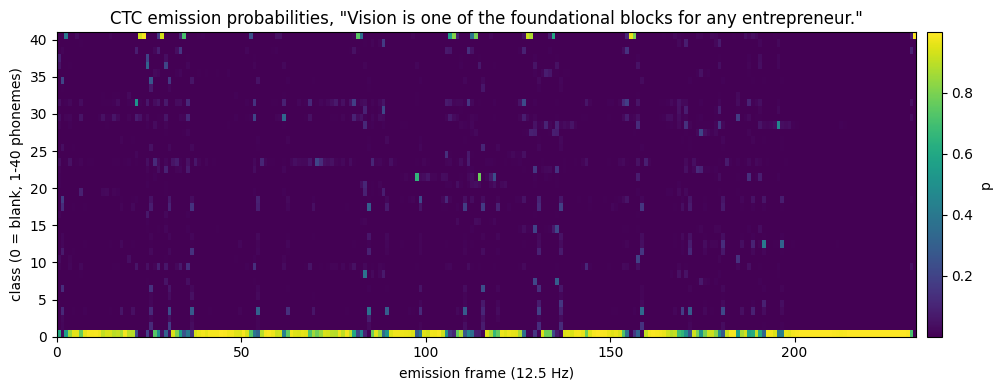

In [8]:
# longest val target
pick = max((val_ds[i] for i in range(len(val_ds))), key=lambda t: len(t.data["target"]))
b = collate([pick])
model.eval()
with torch.no_grad():
    logp, n_valid = model(normalized(b), b.lengths["tx"])
pred = greedy(logp[0], int(n_valid[0]))
ref = pick.data["target"].tolist()
print("sentence :", repr(pick.metadata["text"]))
print("true     :", VOCAB.decode(ref))
print("decoded  :", VOCAB.decode(pred))
print(f"PER      : {levenshtein(pred, ref) / len(ref):.3f}")

probs = logp[0, : int(n_valid[0])].exp().numpy()                       # (T', 41)
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(probs.T, aspect="auto", origin="lower", cmap="viridis", extent=[0, probs.shape[0], 0, VOCAB.n_classes])
ax.set(xlabel="emission frame (12.5 Hz)", ylabel="class (0 = blank, 1-40 phonemes)", title=f'CTC emission probabilities, "{pick.metadata["text"]}"')
fig.colorbar(im, ax=ax, label="p", pad=0.01)
plt.tight_layout()
plt.show()

## Notes

- PER from a small model trained on five days and scored on a sixth. It clears the empty baseline (1.0) but stays far from usable transcription, which is expected at this scale and without a language model.
- The targets are dictionary pronunciations of the prompt. PER measures agreement with that form, not with anything T17 articulated, so a trial where T17 paused or attempted a different wording is still scored against the prompt.
- Closed-loop blocks were recorded while the authors' decoder ran on the same features and showed its output to T17. Their PER is reported separately for that reason.
- Holding out a day makes the split block-disjoint and nearly prompt-disjoint. `loop_type` alone would not: 80 of the 50-word and 77 of the 125k closed-loop prompts also occur in open-loop blocks.
- The three 256-channel April sessions can join this model by slicing every block to the same 256 decoder columns, since the Study permutes each era into one order. A batch sampler grouped by session, or a slice before collation, lets them in.
- Possible improvements include: the 4.5 s pre-go context the authors' training pipeline keeps, their Gaussian smoothing and noise augmentation, the 50-word sessions and the April sessions, a deeper decoder, and a language model (PER to WER).